# ReviewLens AI — Exploratory Data Analysis (EDA)

This notebook performs the Exploratory Data Analysis (EDA) for **ReviewLens AI**, an academic mini-project demonstrating end-to-end ML deployment for product review sentiment classification.

### Objectives:
1. Stream the McAuley-Lab/Amazon Product Reviews dataset (`raw_review_Musical_Instruments`).
2. Preprocess the text in a strict 8-step pipeline (negation-aware stopword removal, lemmatization, contraction expansion).
3. Filter and label raw reviews (Stars 4-5 -> 1 | Stars 1-2 -> 0 | Stars 3 -> Discard).
4. Save clean reviews to `backend/data/processed_reviews.csv`.
5. Visualize class balance, word count distributions, N-grams, negation impact, and word frequencies.

In [1]:
import os
import sys
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Ensure we import preprocessing functions correctly
sys.path.append(os.path.abspath('../backend'))
from ml.preprocessing import clean_review_text, is_valid_review

# Set plotting aesthetics
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print('Setup complete!')

Setup complete!


## 1. Data Acquisition & Streaming

We stream the Amazon Reviews 2023 dataset directly from Hugging Face (`McAuley-Lab/Amazon-Reviews-2023`) for the `raw_review_Musical_Instruments` configuration. This satisfies the requirement R1.1.1 without requiring local Kaggle API key setup.

In [2]:
from datasets import load_dataset

print('Streaming dataset from Hugging Face...')
ds = load_dataset('McAuley-Lab/Amazon-Reviews-2023', 'raw_review_Musical_Instruments', split='full', streaming=True)

raw_samples = []
max_samples = 25000

for i, item in enumerate(ds):
    if len(raw_samples) >= max_samples:
        break
    review_text = item.get('text')
    rating = item.get('rating')
    if review_text is not None and rating is not None:
        raw_samples.append({
            'reviewText': str(review_text),
            'overall': float(rating)
        })

df = pd.DataFrame(raw_samples)
print(f'Loaded {len(df)} raw samples from streaming.')
df.head()

Streaming dataset from Hugging Face...


/home/varad/Documents/himshikhar/mini-project1/.venv/lib/python3.11/site-packages/datasets/load.py:1486: FutureWarning: The repository for McAuley-Lab/Amazon-Reviews-2023 contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/McAuley-Lab/Amazon-Reviews-2023
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this dataset from the next major release of `datasets`.
  warnings.warn(


Loaded 25000 raw samples from streaming.


,reviewText,overall
0,"Great headphones, comfortable and sound is goo...",5.0
1,I like the piano.. but the sustain pedal faile...,3.0
2,pretty good overall. I like it. the controll...,4.0
3,Too bad it didn't work. At least the return pr...,3.0
4,Good and sturdy but the bolt was hell to get o...,5.0


## 2. Text Preprocessing & Labeling

We apply the strict preprocessing pipeline defined in R1.1.4 and R1.1.5, including negation retention, contraction expansion, NLTK tokenization, and lemmatization.

In [3]:
# R1.1.4: 1. Drop null/empty reviewText rows
df = df.dropna(subset=['reviewText'])
df = df[df['reviewText'].str.strip() != '']

# R1.1.3: Labels: Stars 4-5 -> 1 (Positive), Stars 1-2 -> 0 (Negative), Star 3 -> Discard
df = df[df['overall'] != 3.0]
df['label'] = df['overall'].apply(lambda x: 1 if x >= 4.0 else 0)

# Run cleaning
print('Cleaning review text column...')
df['clean_text'] = df['reviewText'].apply(clean_review_text)

# R1.1.5: Drop invalid reviews (non-ASCII, emojis only, < 3 tokens after cleaning)
print('Filtering invalid reviews...')
mask = df.apply(lambda row: is_valid_review(row['reviewText'], row['clean_text']), axis=1)
df = df[mask].reset_index(drop=True)

print(f'Remaining clean reviews: {len(df)}')
df[['reviewText', 'clean_text', 'label']].head()

Cleaning review text column...


Filtering invalid reviews...


Remaining clean reviews: 19418


,reviewText,clean_text,label
0,"Great headphones, comfortable and sound is goo...",great headphone comfortable sound good no comp...,1
1,pretty good overall. I like it. the controll...,pretty good overall like controller not longes...,1
2,Good and sturdy but the bolt was hell to get o...,good sturdy bolt hell get thought glued get ha...,1
3,works great with my tablet,work great tablet,1
4,Xlnt quality. Does NOT work for thick music bo...,xlnt quality not work thick music book xlnt ha...,1


### Export Preprocessed Data
We save the final dataframe consisting only of columns `clean_text` and `label` to `backend/data/processed_reviews.csv`.

In [4]:
os.makedirs('../backend/data', exist_ok=True)
processed_df = df[['clean_text', 'label']]
processed_df.to_csv('../backend/data/processed_reviews.csv', index=False)
print(f'Exported {len(processed_df)} rows to backend/data/processed_reviews.csv')

Exported 19418 rows to backend/data/processed_reviews.csv


## 3. Visualizations & Insights

### A. Class Balance Analysis

Positive reviews: 17554 (90.40%)
Negative reviews: 1864 (9.60%)


/tmp/ipykernel_89712/1712465678.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)
/tmp/ipykernel_89712/1712465678.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Negative (0)', 'Positive (1)'])


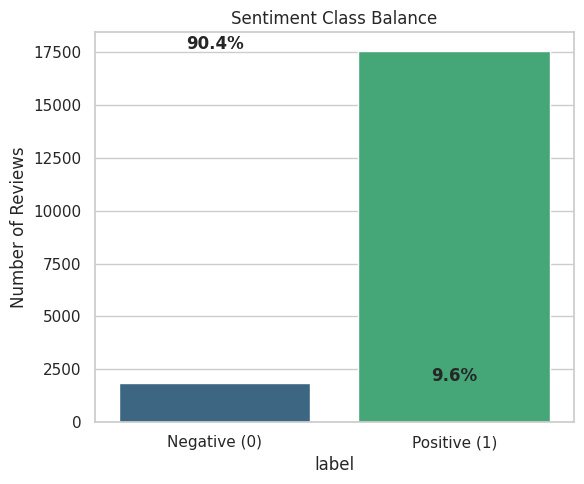

In [5]:
counts = processed_df['label'].value_counts()
percentages = processed_df['label'].value_counts(normalize=True) * 100

print(f'Positive reviews: {counts[1]} ({percentages[1]:.2f}%)')
print(f'Negative reviews: {counts[0]} ({percentages[0]:.2f}%)')

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)
ax.set_xticklabels(['Negative (0)', 'Positive (1)'])
ax.set_title('Sentiment Class Balance')
ax.set_ylabel('Number of Reviews')
for i, val in enumerate(counts.values):
    ax.text(i, val + 100, f'{percentages.values[i]:.1f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### B. Review Length Distribution

Let's compare the word length of raw reviews vs. cleaned reviews split by positive and negative classes.

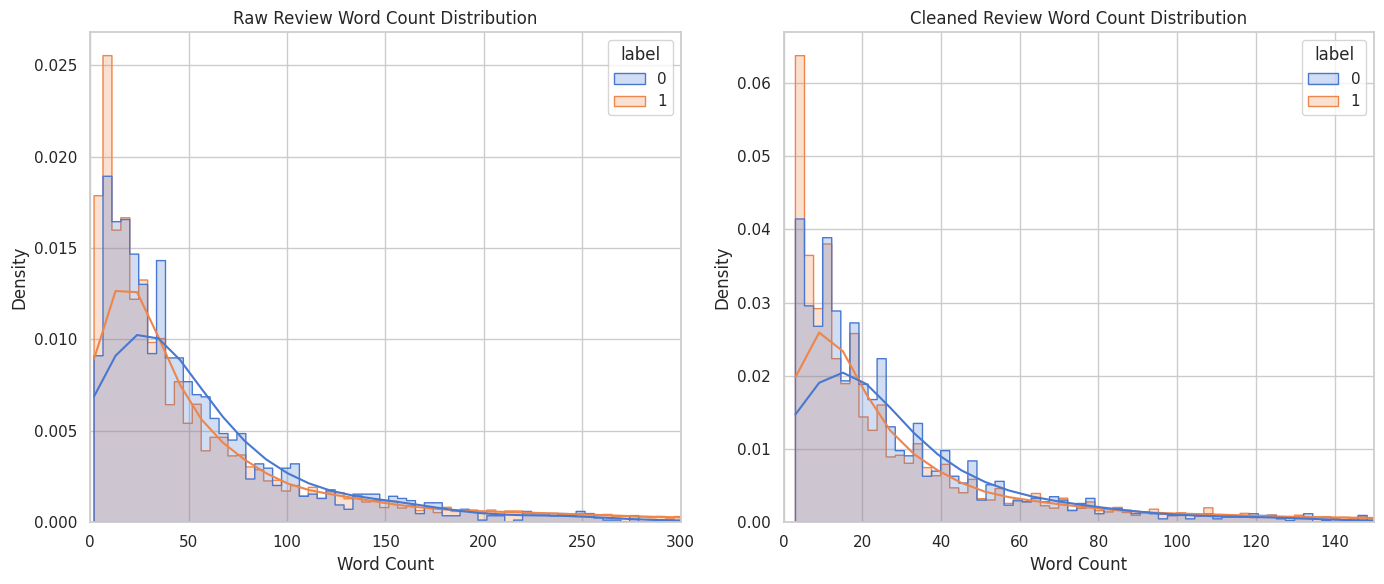

In [6]:
df['raw_word_count'] = df['reviewText'].apply(lambda x: len(str(x).split()))
df['clean_word_count'] = df['clean_text'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)

sns.histplot(data=df, x='raw_word_count', hue='label', element='step', stat='density', common_norm=False, kde=True, palette='muted', ax=axes[0])
axes[0].set_title('Raw Review Word Count Distribution')
axes[0].set_xlabel('Word Count')
axes[0].set_xlim(0, 300)

sns.histplot(data=df, x='clean_word_count', hue='label', element='step', stat='density', common_norm=False, kde=True, palette='muted', ax=axes[1])
axes[1].set_title('Cleaned Review Word Count Distribution')
axes[1].set_xlabel('Word Count')
axes[1].set_xlim(0, 150)

plt.tight_layout()
plt.show()

### C. N-gram Distribution (Unigrams & Bigrams)

Let's analyze the most frequent unigrams and bigrams for each class.

/tmp/ipykernel_89712/4010385897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette='crest', ax=axes[0])
/tmp/ipykernel_89712/4010385897.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette='flare', ax=axes[1])


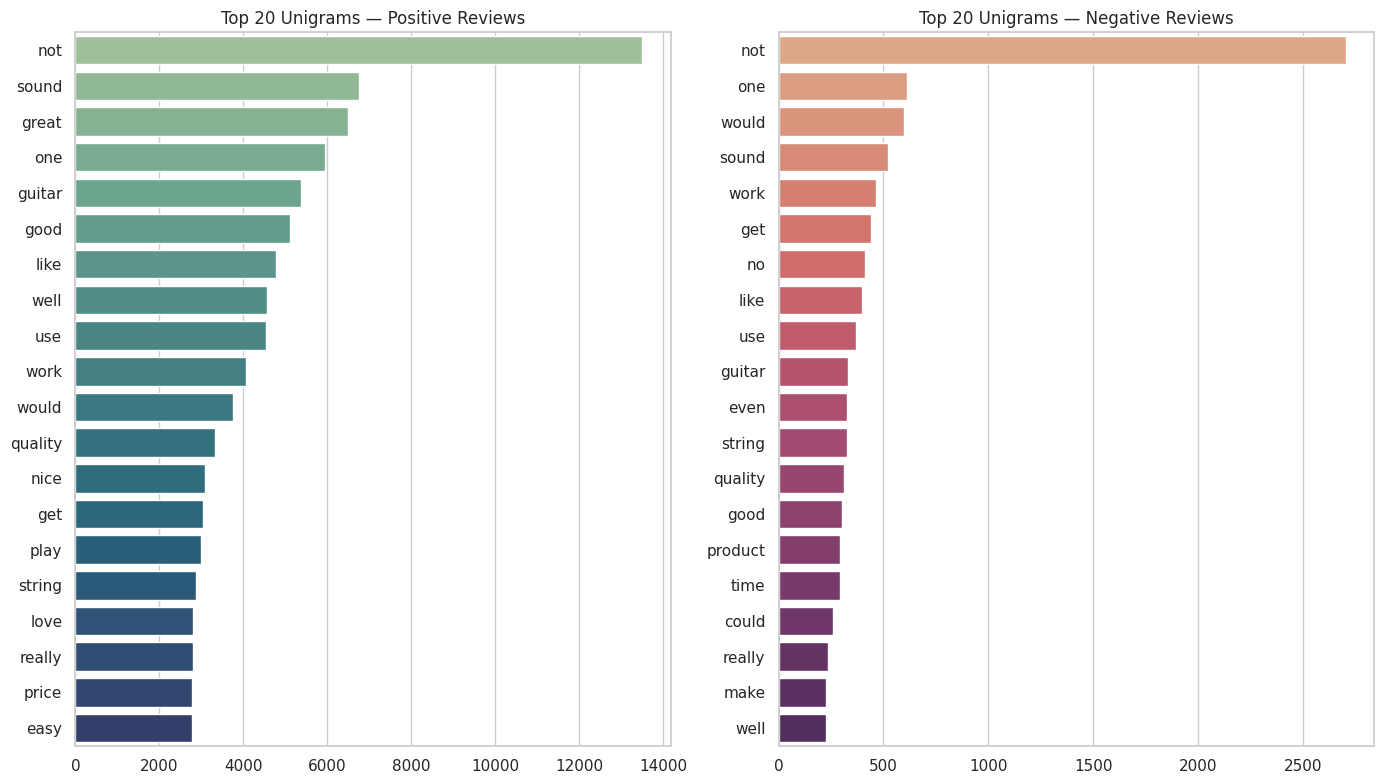

In [7]:
def get_top_ngrams(corpus, n=1, top_k=20):
    words = []
    for text in corpus:
        tokens = text.split()
        if n == 1:
            words.extend(tokens)
        else:
            words.extend([' '.join(tokens[i:i+n]) for i in range(len(tokens)-n+1)])
    return Counter(words).most_common(top_k)

pos_corpus = df[df['label'] == 1]['clean_text']
neg_corpus = df[df['label'] == 0]['clean_text']

top_pos_unigrams = get_top_ngrams(pos_corpus, n=1)
top_neg_unigrams = get_top_ngrams(neg_corpus, n=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

words, counts = zip(*top_pos_unigrams)
sns.barplot(x=list(counts), y=list(words), palette='crest', ax=axes[0])
axes[0].set_title('Top 20 Unigrams — Positive Reviews')

words, counts = zip(*top_neg_unigrams)
sns.barplot(x=list(counts), y=list(words), palette='flare', ax=axes[1])
axes[1].set_title('Top 20 Unigrams — Negative Reviews')

plt.tight_layout()
plt.show()

/tmp/ipykernel_89712/261791093.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette='crest', ax=axes[0])
/tmp/ipykernel_89712/261791093.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette='flare', ax=axes[1])


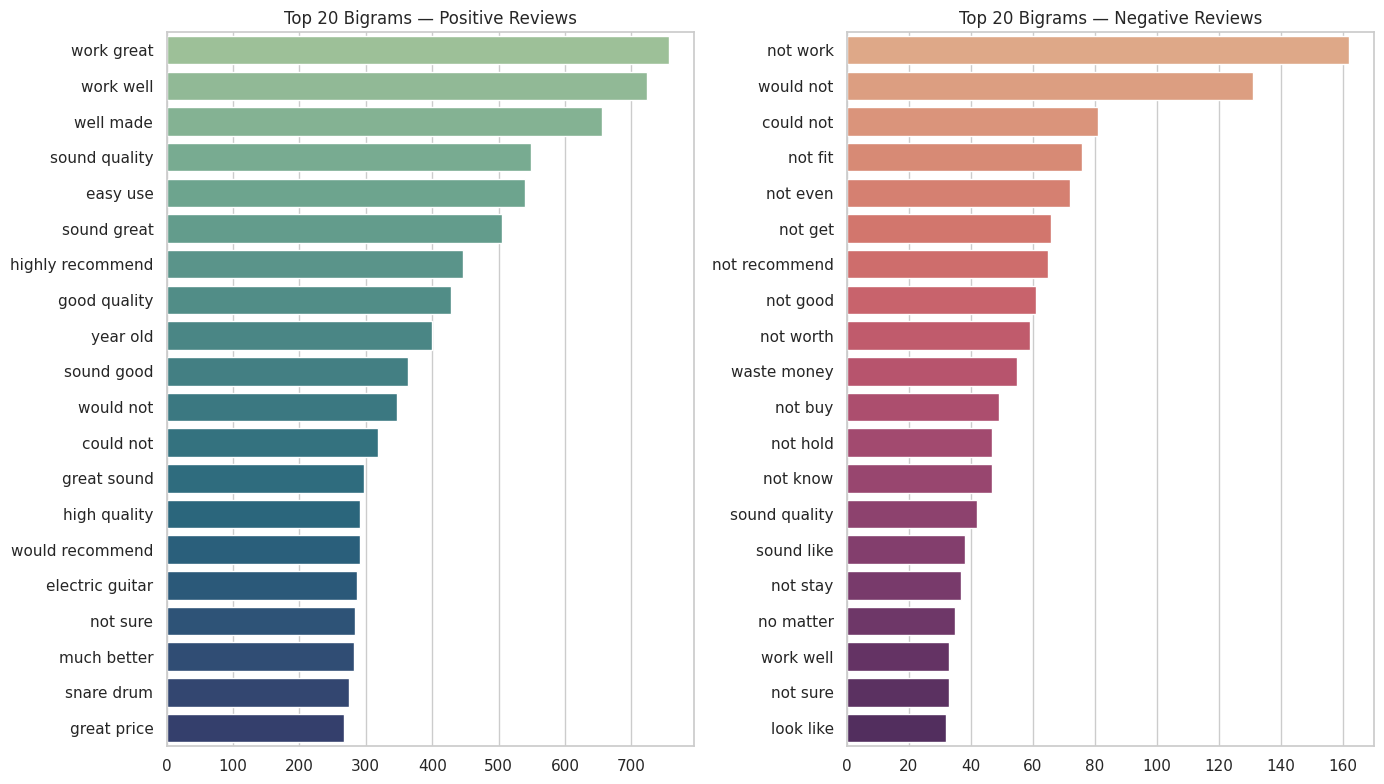

In [8]:
top_pos_bigrams = get_top_ngrams(pos_corpus, n=2)
top_neg_bigrams = get_top_ngrams(neg_corpus, n=2)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

words, counts = zip(*top_pos_bigrams)
sns.barplot(x=list(counts), y=list(words), palette='crest', ax=axes[0])
axes[0].set_title('Top 20 Bigrams — Positive Reviews')

words, counts = zip(*top_neg_bigrams)
sns.barplot(x=list(counts), y=list(words), palette='flare', ax=axes[1])
axes[1].set_title('Top 20 Bigrams — Negative Reviews')

plt.tight_layout()
plt.show()

### D. Negation Impact Analysis

By retaining negation words like `not`, `no`, `never`, `hardly`, and `barely`, our bigrams contain powerful negation phrases. Let's list and plot the top bigrams starting with or containing negation words.

/tmp/ipykernel_89712/2002240788.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette='magma', ax=ax)


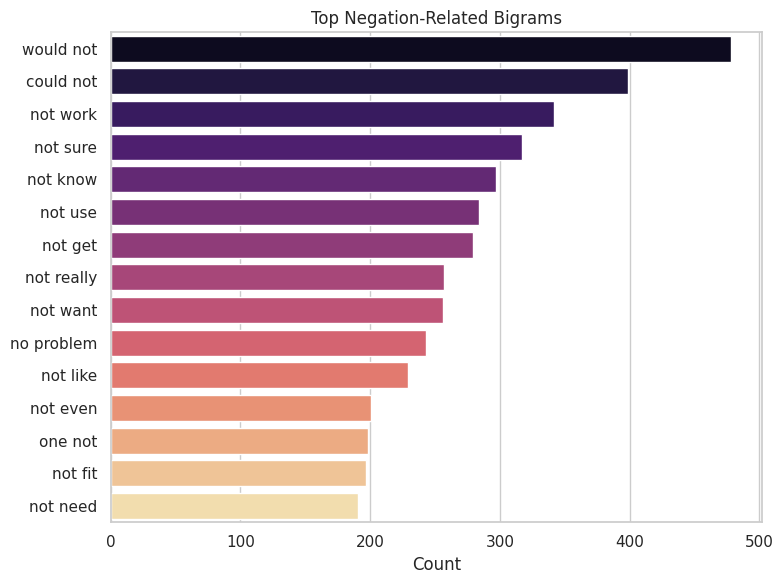

In [9]:
negation_words = {'not', 'no', 'never', 'hardly', 'barely'}

def get_negation_bigrams(corpus, top_k=15):
    bigrams = []
    for text in corpus:
        tokens = text.split()
        for i in range(len(tokens)-1):
            w1, w2 = tokens[i], tokens[i+1]
            if w1 in negation_words or w2 in negation_words:
                bigrams.append(f'{w1} {w2}')
    return Counter(bigrams).most_common(top_k)

neg_bigrams = get_negation_bigrams(df['clean_text'])

fig, ax = plt.subplots(figsize=(8, 6))
words, counts = zip(*neg_bigrams)
sns.barplot(x=list(counts), y=list(words), palette='magma', ax=ax)
ax.set_title('Top Negation-Related Bigrams')
ax.set_xlabel('Count')
plt.tight_layout()
plt.show()

### E. Word Clouds / High-Frequency Term Visualization

We visualize the highest frequency words in each class using a high-quality word cloud or a customized layout if wordcloud packages aren't fully installed.

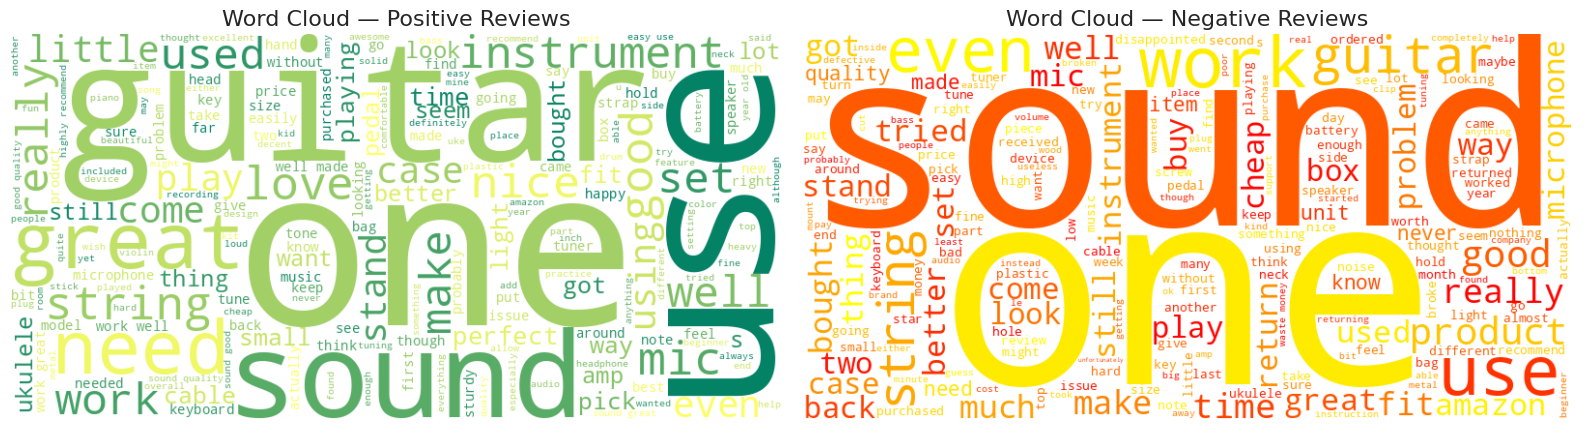

In [10]:
try:
    from wordcloud import WordCloud
    
    pos_text = ' '.join(pos_corpus)
    neg_text = ' '.join(neg_corpus)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    
    wordcloud_pos = WordCloud(width=800, height=400, background_color='white', colormap='summer').generate(pos_text)
    axes[0].imshow(wordcloud_pos, interpolation='bilinear')
    axes[0].set_title('Word Cloud — Positive Reviews', fontsize=16)
    axes[0].axis('off')
    
    wordcloud_neg = WordCloud(width=800, height=400, background_color='white', colormap='autumn').generate(neg_text)
    axes[1].imshow(wordcloud_neg, interpolation='bilinear')
    axes[1].set_title('Word Cloud — Negative Reviews', fontsize=16)
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()
except ImportError:
    print('wordcloud library not installed. Falling back to high-quality frequency plots.')
    # Fallback frequency plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    pos_freq = Counter(' '.join(pos_corpus).split()).most_common(15)
    words, counts = zip(*pos_freq)
    sns.barplot(x=list(counts), y=list(words), palette='summer', ax=axes[0])
    axes[0].set_title('Top Words — Positive')
    
    neg_freq = Counter(' '.join(neg_corpus).split()).most_common(15)
    words, counts = zip(*neg_freq)
    sns.barplot(x=list(counts), y=list(words), palette='autumn', ax=axes[1])
    axes[1].set_title('Top Words — Negative')
    plt.tight_layout()
    plt.show()

## 4. Automated Verification Suite

Asserting that the dataset meets all criteria required for Phase 3 pipeline compatibility.

In [11]:
# Validation suite
assert processed_df.shape[0] >= 10000, f'Error: Dataset has only {len(processed_df)} rows. Needs >= 10,000.'
assert list(processed_df.columns) == ['clean_text', 'label'], 'Error: Columns must be exactly [clean_text, label].'
assert processed_df['label'].isin([0, 1]).all(), 'Error: Labels can only contain 0 or 1.'
assert processed_df['clean_text'].isna().sum() == 0, 'Error: clean_text contains NaN values.'
assert processed_df['clean_text'].apply(lambda x: len(str(x).split()) >= 3).all(), 'Error: Found reviews with < 3 clean tokens.'
print('Validation PASSED! Ready for Phase 3 ML training.')

Validation PASSED! Ready for Phase 3 ML training.
